In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from dataclasses import dataclass
from icecream import ic
from utils import add_min_cols, reset_start_to_zero

In [2]:
df = pl.read_csv("../data/alibaba-2020/generated/merged_dataframes.csv")
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96


In [4]:
df = reset_start_to_zero(df, ["start_time", "end_time"])
df.sort("start_time").head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""a62323fc633f6b2b248fa29c472f2c…","""3b127c8abb4f26e57b34af81""",0,573388,null,null,"""MISC""",8,96
"""8fbbbfd39ca29ee498666bdec9d92d…","""34ff670729b854702064bdb9""",78072,573381,null,null,"""P100""",2,64
"""99b8757c8dad2fbd3160cb10b9df51…","""8822661a76b030d582e9bbb2""",78072,573387,null,null,"""P100""",2,64
"""e7b2a9571e5eba3d628eb4570de65d…","""4aa72ac9bb3b481adc47b818""",78073,573381,null,null,"""P100""",2,64
"""e6401695c75a761b8c17bfa7c0d259…","""df2657c90eebc406289f6dc2""",78104,573382,null,null,"""P100""",2,64


In [5]:
df_gpus = df.filter(df["machine_gpu"].is_not_null())
df_gpus.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",1217125,1217238,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",1494997,1495318,150.497242,50.949074,"""MISC""",8,96
"""7f1f4d76602d2071cb959a7ec47873…","""5248e29b2b7f2b5f8b974608""",1070180,1083941,498.010627,38.279293,"""MISC""",8,96
"""6ecadb953221add9491f244051114c…","""5248e29b2b7f2b5f8b974608""",1071901,1085403,494.623959,36.739657,"""MISC""",8,96
"""66ae3b379970ed9246766f1e7b473b…","""5248e29b2b7f2b5f8b974608""",1237326,1245522,231.566358,45.814088,"""MISC""",8,96


In [6]:
@dataclass(frozen=True, kw_only=True)
class GPUInfo:
    name: str
    passive_power: float
    max_power: float


# TODO: check how realistic is passive power consumption, as far as I know
# is should be between 0 and 10W. So it is not so far off to consider it 5
gpus_dict: dict[str, GPUInfo] = {
    # ref: https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/tesla-product-literature/T4%20Product%20Brief.pdf
    "T4": GPUInfo(name="T4", passive_power=5, max_power=70),
    # ref: https://www.nvidia.com/en-us/data-center/v100/
    "V100": GPUInfo(name="V100", passive_power=5, max_power=275),
    "V100M32": GPUInfo(name="V100", passive_power=5, max_power=275),
    # ref: https://images.nvidia.com/content/tesla/pdf/nvidia-tesla-p100-datasheet.pdf
    "P100": GPUInfo(name="P100", passive_power=5, max_power=300),
    # according to https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020
    # misc is k80, k60 and k40m
    # ref: https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/tesla-product-literature/Tesla-K80-BoardSpec-07317-001-v05.pdf
    "MISC": GPUInfo(name="MISC", passive_power=5, max_power=300),
}

end_time: int = df["end_time"].max()

idle_usage = np.zeros(end_time)
machines_list = df_gpus["machine"].unique().to_numpy()
for machine in machines_list:
    tasks = df_gpus.filter(df_gpus["machine"] == machine)
    passive_power = gpus_dict[tasks["gpu_type"][0]].passive_power
    idle_usage += tasks["cap_gpu"][0] * passive_power
    for start, end, gpu in tasks[["start_time", "end_time", "machine_gpu"]].iter_rows():
        idle_usage[start:end] -= round(gpu / 100.0) * passive_power

idle_usage

array([31980., 31980., 31980., ..., 31965., 31965., 31965.])

<Axes: >

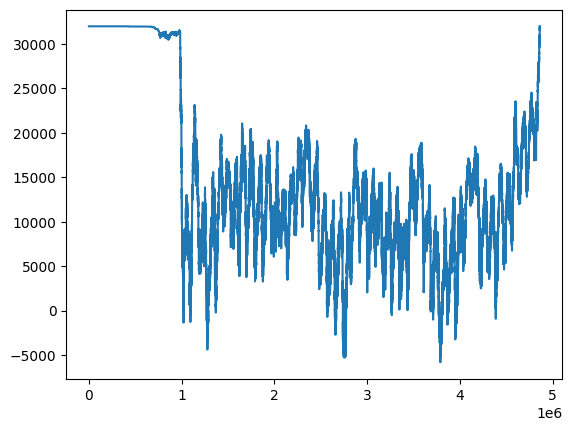

In [7]:
time = np.arange(len(idle_usage))
sns.lineplot(x=time, y=idle_usage)

In [8]:
df_gpus = add_min_cols(df_gpus, ["start_time", "end_time"])
df_gpus.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu,start_time_min,end_time_min
str,str,i64,i64,f64,f64,str,i64,i64,f64,f64
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",1217125,1217238,192.551088,49.391271,"""MISC""",8,96,20285.0,20287.0
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",1494997,1495318,150.497242,50.949074,"""MISC""",8,96,24917.0,24922.0
"""7f1f4d76602d2071cb959a7ec47873…","""5248e29b2b7f2b5f8b974608""",1070180,1083941,498.010627,38.279293,"""MISC""",8,96,17836.0,18066.0
"""6ecadb953221add9491f244051114c…","""5248e29b2b7f2b5f8b974608""",1071901,1085403,494.623959,36.739657,"""MISC""",8,96,17865.0,18090.0
"""66ae3b379970ed9246766f1e7b473b…","""5248e29b2b7f2b5f8b974608""",1237326,1245522,231.566358,45.814088,"""MISC""",8,96,20622.0,20759.0


In [ ]:
def calc_idle_power_usage():
    idle_usage = np.zeros(end_time)
    machines_list = df_gpus["machine"].unique().to_numpy()
    for machine in machines_list:
        tasks = df_gpus.filter(df_gpus["machine"] == machine)
        passive_power = gpus_dict[tasks["gpu_type"][0]].passive_power
        idle_usage += tasks["cap_gpu"][0] * passive_power
        for start, end, gpu in tasks[
            ["start_time", "end_time", "machine_gpu"]
        ].iter_rows():
            idle_usage[start:end] -= round(gpu / 100.0) * passive_power